# 04 · Optimisation — From the upper bound to a realistic action plan

**Project:** Industrial Load Shifting · **Author:** Swaroop Jadhav

### Purpose
notebook 02 found two numbers: **€5,070/year of standby** and an **upper bound of €2,160/year for load shifting**.
The upper bound assumed that every machine's energy can be moved freely within a day. Real production does
not work like that. This notebook asks: *what can the workshop **actually** do, and what is it worth?*

### Business questions
1. How do the machines really run — and what does that allow?
2. **Lever 1:** what does switching standby off outside working hours save?
3. **Lever 2:** what does moving the shift later in summer save?
4. **Lever 3:** does planning the shift start every week with the forecast save more?
5. What is the **realistic action plan** for the plant manager?

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().parent / "src"))
import config
import cost
import forecast as fc
import optimise as op

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.figsize": (11, 4.5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#898781", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "font.size": 10, "axes.titleweight": "bold", "axes.titlesize": 12,
})
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
LABELS = config.SPARK_MACHINES

def save(fig, name):
    fig.savefig(config.FIGURES_DIR / f"{name}.png", bbox_inches="tight")

def euro(x):
    return f"€{x:,.0f}"

loads = pd.read_csv(config.SPARK_LOAD_FILE, parse_dates=["timestamp_utc"])
prices = pd.read_csv(config.PRICES_RAW_FILE, parse_dates=["timestamp_utc"])
aligned = cost.align_load_to_prices(loads, prices)
baseline_total = cost.baseline_cost(aligned).loc["TOTAL", "cost_eur"]
upper_bound = cost.savings_upper_bound(aligned).loc["TOTAL"]
print(f"Baseline (Week 2): {euro(baseline_total)} per year | "
      f"standby {euro(upper_bound['standby_cost_eur'])} | shifting upper bound {euro(upper_bound['max_saving_eur'])}")

Baseline (Week 2): €10,573 per year | standby €5,072 | shifting upper bound €2,157


---
## Part A · How do the machines really run?

A production **run** = consecutive quarter-hours where the machine works above 10% of its typical peak.
The median run length tells us what kind of machine it is (decision D14):

| Type | Median run | Example | Can it be moved? |
|---|---|---|---|
| **continuous** | > 24 h | wire EDM running for days | ❌ no — it never stops |
| **shift-bound** | 2–24 h | mills and lathes: one block per working day | only if the **whole shift** moves |
| **cycling** | < 2 h | coolers switching on and off | follows the heat load of the workshop |

In [2]:
classes = op.classify_machines(aligned).rename(index=LABELS)
classes.round(1)

,production_mwh,runs,median_run_h,weekend_share_%,type
machine,,,,,
MV 2400 R (wire EDM),11.4,65,48.2,1.5,continuous
CF ST 161 (water chiller),8.7,181,0.8,21.0,cycling
JWA 24 (liquid cooler),7.1,1289,0.5,11.8,cycling
DNG 50 evo (mill),6.5,634,1.0,2.4,cycling
DMU 125 (5-axis mill),6.2,164,8.4,0.9,shift-bound
Chiron 800 (5-axis mill),6.0,220,9.2,0.2,shift-bound
CTX 800 TC (lathe-mill),2.6,168,8.0,3.5,shift-bound
E110 (lathe),2.4,157,8.2,3.6,shift-bound
E30 D2 (lathe),0.6,192,8.1,4.1,shift-bound


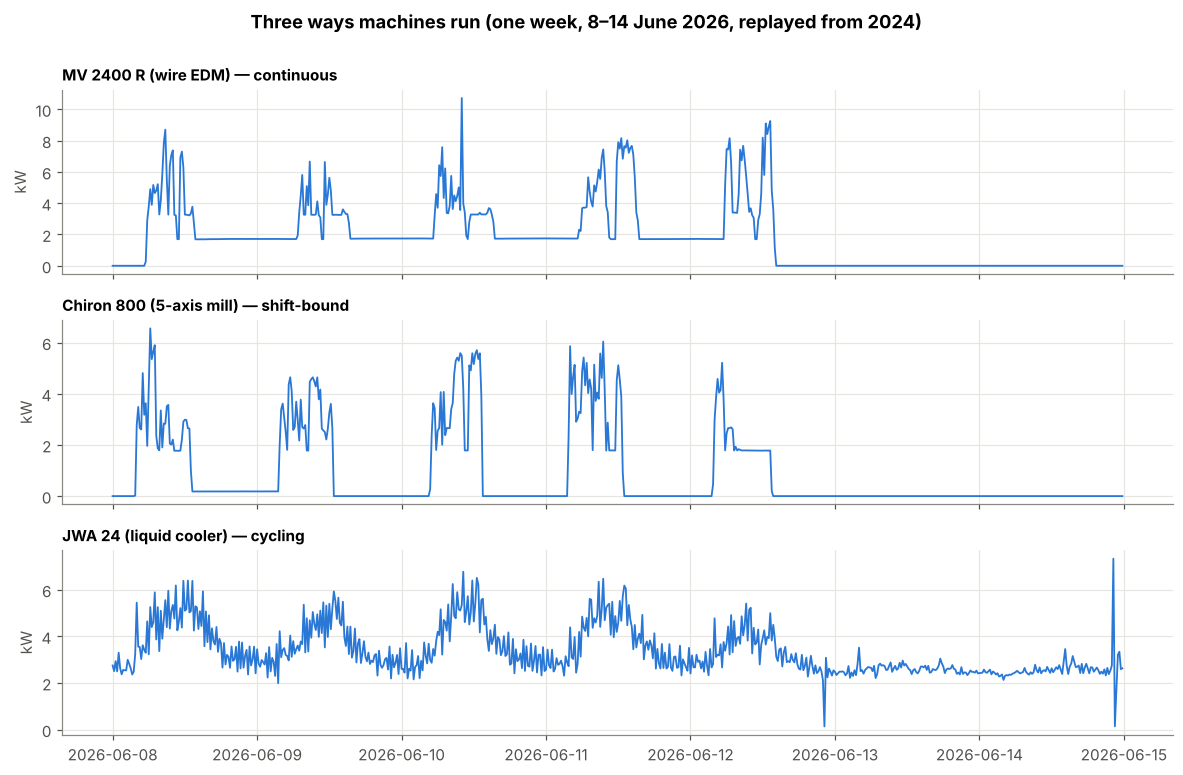

In [3]:
week = aligned[(aligned["timestamp_local"] >= "2026-06-08") & (aligned["timestamp_local"] < "2026-06-15")]
examples = [("TEC_MV2400R", "continuous"), ("TEC_Chiron800", "shift-bound"), ("TEC_JWA24", "cycling")]
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
for ax, (m, kind) in zip(axes, examples):
    ax.plot(week["timestamp_local"], week[m] * 4, color=COLORS[0], linewidth=1.2)
    ax.set_title(f"{LABELS[m]} — {kind}", loc="left", fontsize=10)
    ax.set_ylabel("kW")
fig.suptitle("Three ways machines run (one week, 8–14 June 2026, replayed from 2024)", fontweight="bold", y=1.0)
fig.tight_layout()
save(fig, "W4_A_machine_types")
plt.show()

**Interpretation**

The three types look very different. The wire EDM never really stops during the week: it has heavier work during the day, but in between it stays at around 2 kW and only switches off on the weekend. Its median run lasts 48 hours. The Chiron 800 is a typical shift machine: it starts at around 04:00 to 05:00, runs one block of about 9 hours and is then off until the next morning. The JWA 24 liquid cooler switches on and off every few minutes, all day and night, and its load goes up during working hours and down at night and on the weekend, so it follows the heat from the machines.

This is why the notebook 02 upper bound cannot be reached. It assumed that energy can be moved freely into the cheapest quarter-hours, but in reality there are no small jobs to move around. The EDM cannot be interrupted, and the mills and lathes run as one block that is basically the shift itself. So in this workshop, load shifting does not mean moving single jobs. It means changing when the whole shift starts.

---
## Part B · Lever 1: switch standby off outside working hours

**Rule:** standby stays **on** Monday–Friday from **03:00 to 17:00** (1 h warm-up before the earliest shift start
at 04:00, plus a buffer after the shift). Outside that — nights and weekends — it is **switched off**.

⚠️ This must be checked with the operators first (assumption A9): some machines are kept warm on purpose for accuracy.

In [4]:
standby = pd.DataFrame([op.standby_off_saving(aligned, m) for m in aligned.attrs["machines"]]).set_index("machine")
standby = standby[standby["saved_eur"] > 1].sort_values("saved_eur", ascending=False).rename(index=LABELS)
print(f"Lever 1 total: {euro(standby['saved_eur'].sum())} per year, {standby['saved_mwh'].sum():.1f} MWh "
      f"({100 * standby['saved_eur'].sum() / upper_bound['standby_cost_eur']:.0f}% of all standby cost)")
standby.round(1)

Lever 1 total: €3,064 per year, 27.9 MWh (60% of all standby cost)


,standby_kw,saved_mwh,saved_eur
machine,,,
DNG 50 evo (mill),4.1,20.7,2247.9
JWA 24 (liquid cooler),2.1,6.8,772.7
CF ST 161 (water chiller),0.1,0.4,43.8


**Interpretation**

Switching standby off outside working hours would save about €3,060 per year (27.9 MWh). Almost all of it comes from the DNG 50 evo (€2,248) and the JWA 24 liquid cooler (€773), the CF ST 161 chiller adds only €44.

It is not 100% of the standby cost (€5,072) because the machines still need their standby during the working day. In my rule, standby stays on from Monday to Friday between 03:00 and 17:00, so the warm-up before the shift and the time after the shift are covered. Only nights and weekends are switched off, which is about 60% of the standby cost.

Before recommending this, I would ask the operators why the DNG 50 evo is never switched off. If it is kept warm to stay accurate, a full shutdown could cause quality problems, and a shorter warm-up or an eco mode might be the better solution. For the liquid cooler I would check which machine or process it serves, because it might also be needed at night.

---
## Part C · Lever 2: move the shift later in summer

All **shift-bound** and **cycling** machines move with the shift (coolers follow the workshop's heat load, assumption A8).
The **continuous** wire EDM stays as it is. We test moving the weekday shift by whole hours — the same every working day —
and look at each month separately.

In [5]:
movable = [m for m, row in op.classify_machines(aligned).iterrows() if row["type"] != "continuous"]
energy = op.production_matrix(aligned, movable)
price = fc.price_matrix(prices)
base_movable = op.matrix_cost(energy, price).sum()
print(f"Movable production energy: {energy.to_numpy().sum() / 1000:.1f} MWh, costing {euro(base_movable)} per year")

table = op.offset_table(energy, price, hours=range(-2, 7))
table.index.name = "month"
table.columns = [f"{h:+d} h" for h in table.columns]
table.round(0)

Movable production energy: 40.7 MWh, costing €4,246 per year


,-2 h,-1 h,+0 h,+1 h,+2 h,+3 h,+4 h,+5 h,+6 h
month,,,,,,,,,
2025-10,7.0,2.0,0.0,-3.0,-4.0,-3.0,-2.0,-10.0,-25.0
2025-11,28.0,13.0,0.0,-12.0,-21.0,-25.0,-28.0,-30.0,-32.0
2025-12,6.0,3.0,0.0,-3.0,-5.0,-7.0,-8.0,-9.0,-9.0
2026-01,15.0,7.0,0.0,-5.0,-7.0,-9.0,-9.0,-7.0,-5.0
2026-02,0.0,-0.0,0.0,2.0,3.0,3.0,0.0,-2.0,-4.0
2026-03,-28.0,-14.0,0.0,12.0,15.0,8.0,-11.0,-35.0,-58.0
2026-04,-37.0,-20.0,0.0,22.0,45.0,63.0,71.0,64.0,43.0
2026-05,-21.0,-12.0,0.0,14.0,27.0,35.0,36.0,29.0,14.0
2026-06,-32.0,-17.0,0.0,18.0,36.0,48.0,50.0,39.0,10.0


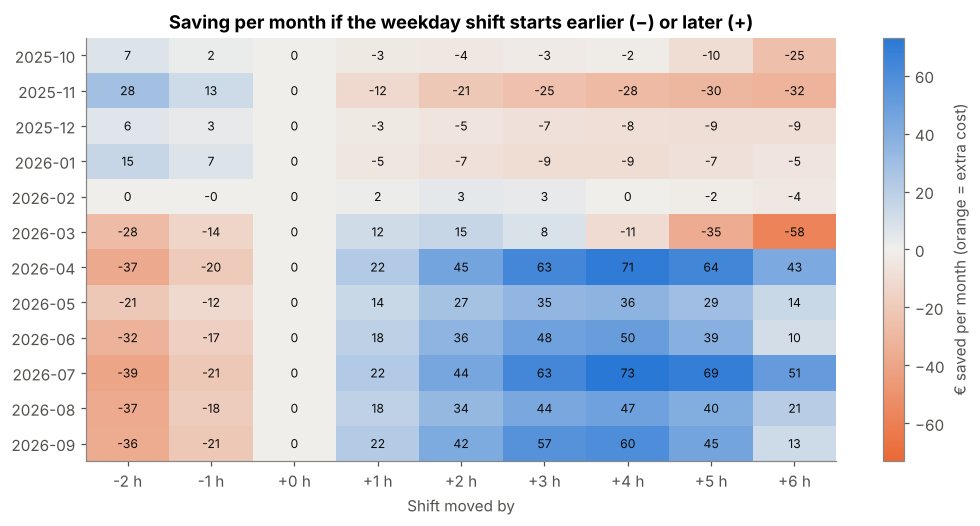

In [6]:
cmap = LinearSegmentedColormap.from_list("cost_saving", ["#eb6834", "#f0efec", "#2a78d6"])
lim = np.abs(table.to_numpy()).max()
fig, ax = plt.subplots(figsize=(11, 5))
im = ax.imshow(table.to_numpy(), aspect="auto", cmap=cmap, norm=TwoSlopeNorm(0, -lim, lim))
ax.set_xticks(range(len(table.columns))); ax.set_xticklabels(table.columns)
ax.set_yticks(range(len(table))); ax.set_yticklabels(table.index)
for (i, j), v in np.ndenumerate(table.to_numpy()):
    ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="#0b0b0b")
ax.grid(False)
fig.colorbar(im, ax=ax).set_label("€ saved per month (orange = extra cost)")
ax.set(title="Saving per month if the weekday shift starts earlier (−) or later (+)", xlabel="Shift moved by")
save(fig, "W4_C_shift_heatmap")
plt.show()

In [7]:
rules = {"Same shift all year (today)": pd.Series(0, index=energy.index)}
for h in (2, 3, 4):
    rules[f"Summer schedule: Apr–Sep +{h} h"] = op.seasonal_offsets(energy.index, h)
rule_saving = pd.Series({name: base_movable - op.matrix_cost(op.apply_offsets(energy, offs), price).sum()
                         for name, offs in rules.items()}, name="saving_eur")
rule_saving.round(0).to_frame()

,saving_eur
Same shift all year (today),0.0
Summer schedule: Apr–Sep +2 h,228.0
Summer schedule: Apr–Sep +3 h,309.0
Summer schedule: Apr–Sep +4 h,337.0


**Interpretation**

A later shift saves money from April to September and costs extra from October to January. In summer, the midday solar dip is strong, so moving the shift 4 hours later shifts more of the work into the cheap hours around 12:00 to 15:00 and away from the morning peak. The best months are July (€73) and April (€71). In winter there is almost no midday dip and the evening peak starts earlier, so a later shift runs into more expensive hours, for example −€28 in November. February and March are in between.

Over the year, a summer schedule with the shift starting 4 hours later saves €337, 3 hours later €309 and 2 hours later €228. I would recommend +3 or +4 hours. +3 hours gives 92% of the saving with more normal working hours: the shift would start at around 08:00 instead of 05:00. For the workers this means starting later but also finishing later in the evening, which some may like and others not, for example people with children. It would also need to fit the working-time rules and could make the afternoons in the workshop hotter in summer.

---
## Part D · Lever 3: plan the shift start every week with the forecast

Every Friday after the noon auction, the planner picks **one** shift start for the next Monday–Friday
(0 to +4 h later than today), using the **7-day-average forecast** from notebook 03 (Monday = 3 days ahead … Friday = 7).
We compare with the same weekly choice made with **perfect knowledge** of the prices.

In [8]:
weekly_fc = op.weekly_forecast_offsets(energy, prices)
weekly_perfect = op.perfect_weekly_offsets(energy, price)
summer4 = op.seasonal_offsets(energy.index, 4)
lever3 = {
    "Weekly plan with forecast": base_movable - op.matrix_cost(op.apply_offsets(energy, weekly_fc), price).sum(),
    "Weekly plan with perfect knowledge": base_movable - op.matrix_cost(op.apply_offsets(energy, weekly_perfect), price).sum(),
    "Summer schedule +4 h (Lever 2)": rule_saving["Summer schedule: Apr–Sep +4 h"],
}
print(f"Forecast captures {100 * lever3['Weekly plan with forecast'] / lever3['Weekly plan with perfect knowledge']:.0f}% "
      "of the perfect weekly plan")
pd.Series(lever3, name="saving_eur").round(0).to_frame()

Forecast captures 97% of the perfect weekly plan


,saving_eur
Weekly plan with forecast,365.0
Weekly plan with perfect knowledge,374.0
Summer schedule +4 h (Lever 2),337.0


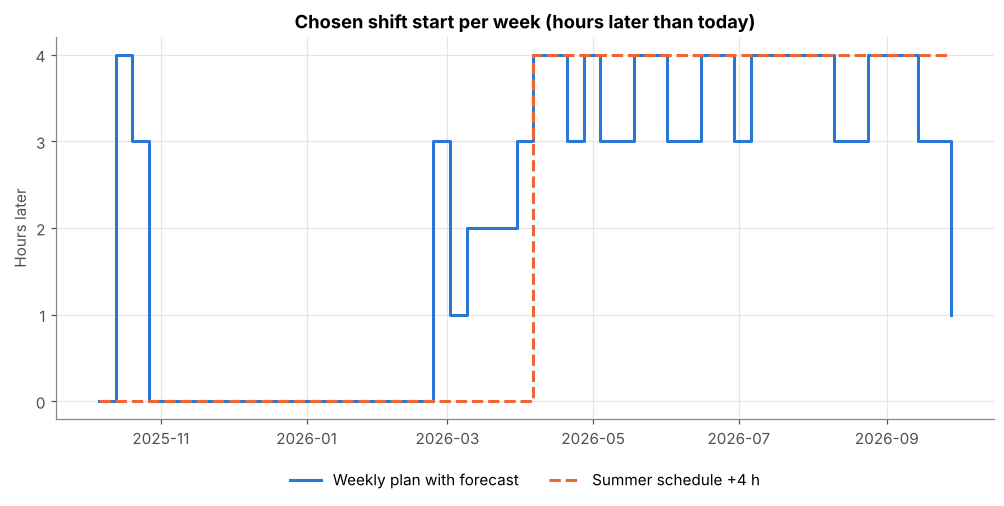

In [9]:
mondays = energy.index[energy.index.day_of_week == 0]
fig, ax = plt.subplots()
ax.step(mondays, weekly_fc.loc[mondays], where="post", color=COLORS[0], label="Weekly plan with forecast")
ax.step(mondays, summer4.loc[mondays], where="post", color=COLORS[1], linestyle="--", label="Summer schedule +4 h")
ax.set(title="Chosen shift start per week (hours later than today)", ylabel="Hours later", yticks=range(0, 5))
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncols=2)
save(fig, "W4_D_weekly_plan")
plt.show()

**Interpretation**

The weekly plan with the forecast saves €365 per year, which is 97% of what the same plan would save with perfect knowledge of the prices (€374). So the 7-day average forecast from notebook 03 is good enough for this decision.

Interestingly, the weekly plan basically finds the summer schedule by itself: it keeps the normal shift in winter and moves it 3 to 4 hours later from about April to September. That is why the fixed summer schedule (€337) gets 92% of the weekly plan's saving. The extra €28 per year is not worth it, because changing the working hours every week would be much harder to organise for the workers and the production planning. A fixed rule that everybody knows in advance is the better choice here.

---
## Part E · The realistic action plan

Recommended combination: **Lever 1 + Lever 2**. Lever 3 is an *alternative* to Lever 2 (not on top of it).
When the shift moves later in summer, the standby window moves with it, so Lever 1 is recalculated together with Lever 2.

In [10]:
lever1_combined = sum(op.standby_off_saving(aligned, m, shift_offsets=summer4)["saved_eur"]
                      for m in aligned.attrs["machines"])
lever2 = rule_saving["Summer schedule: Apr–Sep +4 h"]
plan = pd.DataFrame([
    {"action": "1. Switch standby off outside working hours", "saving_eur": lever1_combined,
     "effort": "low (timer / shutdown routine)", "check first": "why machines stay on (warm-up, accuracy)"},
    {"action": "2. Summer schedule: shift starts 4 h later (Apr–Sep)", "saving_eur": lever2,
     "effort": "medium (staff agreement)", "check first": "working-time rules, workers' preferences"},
]).set_index("action")
total = plan["saving_eur"].sum()
print(f"Realistic saving: {euro(total)} per year = {100 * total / baseline_total:.0f}% of the {euro(baseline_total)} baseline")
print(f"For comparison - Week 2 shifting upper bound: {euro(upper_bound['max_saving_eur'])}, "
      f"realistic shifting (Lever 2): {euro(lever2)} = {100 * lever2 / upper_bound['max_saving_eur']:.0f}% of it")
plan.round(0)

Realistic saving: €3,298 per year = 31% of the €10,573 baseline
For comparison - Week 2 shifting upper bound: €2,157, realistic shifting (Lever 2): €337 = 16% of it


,saving_eur,effort,check first
action,,,
1. Switch standby off outside working hours,2960.0,low (timer / shutdown routine),"why machines stay on (warm-up, accuracy)"
2. Summer schedule: shift starts 4 h later (Apr–Sep),337.0,medium (staff agreement),"working-time rules, workers' preferences"


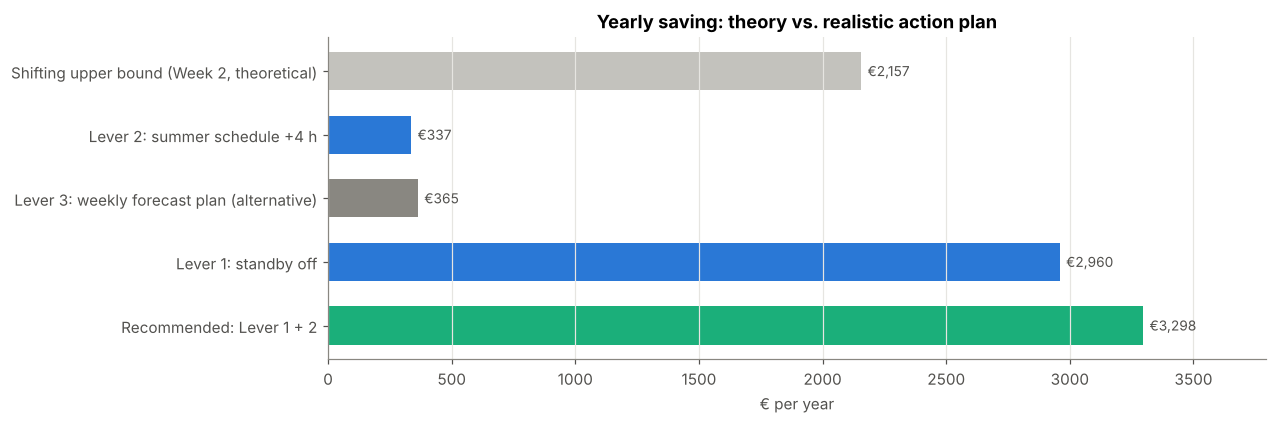

In [11]:
bars = pd.Series({
    "Shifting upper bound (Week 2, theoretical)": upper_bound["max_saving_eur"],
    "Lever 2: summer schedule +4 h": lever2,
    "Lever 3: weekly forecast plan (alternative)": lever3["Weekly plan with forecast"],
    "Lever 1: standby off": lever1_combined,
    "Recommended: Lever 1 + 2": total,
}).iloc[::-1]
colors = [COLORS[2], COLORS[0], "#898781", COLORS[0], "#c3c2bd"]
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.barh(bars.index, bars.values, color=colors, height=0.6)
for y, v in enumerate(bars.values):
    ax.annotate(euro(v), xy=(v, y), xytext=(4, 0), textcoords="offset points", va="center",
                color="#52514e", fontsize=9)
ax.set(title="Yearly saving: theory vs. realistic action plan", xlabel="€ per year", xlim=(0, bars.max() * 1.15))
ax.grid(axis="y", visible=False)
save(fig, "W4_E_action_plan")
plt.show()

**Interpretation**

My recommendation is to start with the standby: switching off the DNG 50 evo and the JWA 24 cooler at night and on the weekend saves about €2,960 per year with low effort, but the operators first have to confirm that the machines do not need to stay warm. The second step is a summer schedule, where the shift starts about 4 hours later from April to September, which saves another €337 per year but needs an agreement with the workers. Together this is about €3,300 per year, or 31% of the electricity bill of €10,573.

Compared with notebook 02, realistic load shifting only reaches 16% of the theoretical upper bound (€337 vs €2,157), because the machines cannot be moved freely. So for this workshop the biggest lever is not when the machines run, but that some of them never switch off.

---
## Key findings

1. The machines cannot be moved freely: the wire EDM runs continuously for days, the mills and lathes run one block per shift, and the coolers follow the heat load. Load shifting here means moving the whole shift, not single jobs.
2. Switching standby off at night and on the weekend saves about €2,960 per year (mainly DNG 50 evo and JWA 24), which is the biggest and easiest lever, but it has to be checked with the operators first.
3. Starting the shift later only pays off from April to September, when the midday solar dip is strong. A summer schedule (+4 h) saves €337 per year, while a later shift in winter would cost extra.
4. Planning the shift start every week with the forecast saves €365 (97% of perfect knowledge), but the fixed summer schedule gets 92% of that with one simple rule, so it is the better choice for the workers.
5. The realistic action plan saves about €3,300 per year (31% of the bill). Realistic load shifting reaches only 16% of the notebook 02 upper bound, so the main problem in this workshop is standby, not timing.

## Next step
Put the results into a **dashboard** for the plant manager, and add the **CO₂ view**: does the summer schedule
also use cleaner electricity (more solar at midday)?